In [30]:
import numpy as np
import pandas as pd

In [31]:
df=pd.read_csv("C:/Users/Tufail/Desktop/Makshu/Jupyter/CsvFile/powerplant_data.csv")

In [32]:
df.head()

,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


In [33]:
#AT-->Atomesphere Temperature
#V-->  Vaccume
#Ap--> pressure
#RH-->Humidity

#PE-->produced energy

In [34]:
df.isnull().sum()

AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

In [35]:
X=df.drop("PE",axis=1)
y=df["PE"]

In [36]:
#train test split
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.2,random_state=42
)

In [37]:
df.shape

(9568, 5)

In [38]:
from sklearn.preprocessing import StandardScaler

scale=StandardScaler()

X_train_scale=scale.fit_transform(X_train)
X_test_scale=scale.transform(X_test)

In [39]:
import torch
import torch.nn as nn

In [40]:
X_train_tensor=torch.tensor(X_train_scale,dtype=torch.float32)
y_train_tensor=torch.tensor(y_train.values,dtype=torch.float32).view(-1,1)

X_test_tensor=torch.tensor(X_test_scale,dtype=torch.float32)
y_test_tensor=torch.tensor(y_test.values,dtype=torch.float32).view(-1,1)

In [41]:
type(X_train_scale)

numpy.ndarray

In [42]:
print(type(y_train))  #this is reason we use diretly access values and view user becauese (n,) to (n,1) 
y_train.shape

<class 'pandas.Series'>


(7654,)

In [43]:
from torch.utils.data import TensorDataset,DataLoader

train_dataset=TensorDataset(X_train_tensor,y_train_tensor)
test_dataset=TensorDataset(X_test_tensor,y_test_tensor)

In [44]:
train_loader=DataLoader(train_dataset,batch_size=32,shuffle=True)
test_loader=DataLoader(test_dataset,batch_size=32)

# Deep Learning

In [45]:
#define our ANN Model

class ANN(nn.Module):
    def __init__(self):
        super(ANN,self).__init__()

        self.model=nn.Sequential(
            #1st hidden layer
            nn.Linear(X_train.shape[1],6),
            nn.ReLU(),
    
            #2nd hidden layer
            nn.Linear(6,6),
            nn.ReLU(),
    
            #output layer
            nn.Linear(6,1)   
    )

    def forward(self,x):
        return self.model(x)

In [46]:
import torch.optim as optiom

model=ANN()

#loss,optimizer
crietrion=nn.MSELoss()
optimizer=optiom.Adam(model.parameters())

In [47]:
#Train the ANN

train_losses=[]
val_losses=[]

best_val_loss=float("inf")

epochs=100

for epoch in range(epochs):
    model.train()
    running_loss=0.0 #tot training loss for 1 epoch

    for xb,yb in train_loader:
        #xb-->feature of 1 batch
        #yb-->labels of 1 batch
        optimizer.zero_grad()

        
        outputs=model(xb)  #forward prop... predicted output
        loss=crietrion(outputs,yb)  #compute loss
        loss.backward() #back prop.. compute gradient
        optimizer.step() #param update

        running_loss+=loss.item() #loss is a tensor --> py float

    epoch_train_loss=running_loss/len(train_loader)
    train_losses.append(epoch_train_loss)


    #validation
    model.eval()
    running_val_loss=0.0

    with torch.no_grad():  #no gradient compute
        for xb,yb in test_loader:
            outputs=model(xb)
            loss=crietrion(outputs,yb)
            running_val_loss+=loss


    epoch_val_loss=running_val_loss/len(test_loader)
    val_losses.append(epoch_val_loss)


    print(f"epoch {epoch+1}/{epochs}==> train loss =${epoch_train_loss} & val loss= ${epoch_val_loss}")


    if epoch_val_loss<best_val_loss:
        best_val_loss=epoch_val_loss
        torch.save(model.state_dict(),"powerplant best_model.pt") #.pt .pth to save file
    

epoch 1/100==> train loss =$206313.42884114583 & val loss= $205167.421875
epoch 2/100==> train loss =$202576.66888020834 & val loss= $198007.5
epoch 3/100==> train loss =$190239.625 & val loss= $180188.78125
epoch 4/100==> train loss =$166620.35494791667 & val loss= $151312.890625
epoch 5/100==> train loss =$134014.16842447917 & val loss= $116235.5078125
epoch 6/100==> train loss =$99026.68528645833 & val loss= $82719.484375
epoch 7/100==> train loss =$69049.05940755208 & val loss= $56965.69140625
epoch 8/100==> train loss =$47943.31408691406 & val loss= $40098.03515625
epoch 9/100==> train loss =$34611.669612630205 & val loss= $29451.7734375
epoch 10/100==> train loss =$26060.465885416666 & val loss= $22658.1328125
epoch 11/100==> train loss =$20561.48095296224 & val loss= $18250.607421875
epoch 12/100==> train loss =$16891.92673339844 & val loss= $15170.73046875
epoch 13/100==> train loss =$14166.103647867838 & val loss= $12674.3271484375
epoch 14/100==> train loss =$11725.2205505371

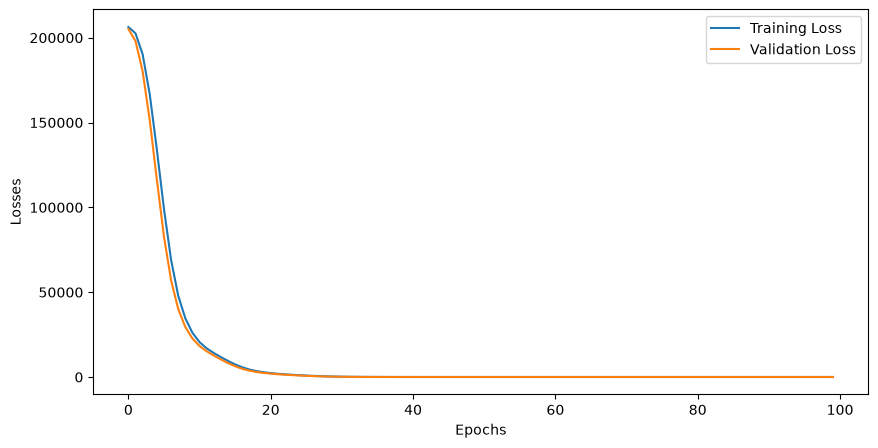

In [48]:
import matplotlib.pyplot as plt

loss_df=pd.DataFrame({
   "Training Loss":train_losses,
   "Validation Loss":val_losses
})

plt.figure(figsize=(10,5))
plt.plot(loss_df["Training Loss"],label="Training Loss")
plt.plot(loss_df["Validation Loss"],label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Losses")

plt.legend()

In [49]:
#lording the best model
model.load_state_dict(torch.load("powerplant best_model.pt"))

<All keys matched successfully>

In [50]:
#Evaluate our Model
model.eval()
with torch.no_grad():
    train_pred=model(X_train_tensor)
    test_pred=model(X_test_tensor)

    train_msr_loss=crietrion(train_pred,y_train_tensor)
    test_msr_loss=crietrion(test_pred,y_test_tensor)

print("Training MSE",train_msr_loss.item())
print("Testing MSE",test_msr_loss.item())

Training MSE 20.590726852416992
Testing MSE 18.794660568237305


In [51]:
from sklearn.metrics import r2_score

print("r2_score",r2_score(y_test,test_pred))

r2_score 0.9343175095600135


In [52]:
predicted_df=pd.DataFrame(test_pred.numpy(),columns=["Predicated Values"])
actual_df=pd.DataFrame(y_test.values,columns=["Actual Values"])

pd.concat([predicted_df,actual_df],axis=1)

,Predicated Values,Actual Values
0,434.996826,433.27
1,436.961609,438.16
2,461.262543,458.42
3,476.325531,480.82
4,435.198792,441.41
...,...,...
1909,451.267395,456.70
1910,431.539520,438.04
1911,467.316467,467.80
1912,431.020569,437.14


In [ ]:
## we can use ml model to check which model is best